<a href="https://colab.research.google.com/github/sandesh0shinde/handwritten-digit-recognition/blob/main/handwritten_digit_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Handwritten Digit Recognition Using Machine Learning

## 1. Introduction

Handwritten Digit Recognition is a Machine Learning project that identifies handwritten numbers from images.

In this project, I will build a model that can recognize digits from 0 to 9. I will use the MNIST dataset, which contains images of handwritten digits.

This project will help me understand image data, classification, model training, and model evaluation using Python.

## 2. Project Objectives

- To learn the basics of image classification.
- To load and explore the MNIST dataset.
- To prepare image data for Machine Learning.
- To train a classification model.
- To evaluate the model's accuracy.
- To predict handwritten digits using the trained model.

## 3. Importing Required Libraries

In this step, I will import the Python libraries needed for the project.

These libraries will help me load the dataset, display handwritten digit images, prepare the data, train the Machine Learning model, and evaluate its performance.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## 4. Loading the Dataset

In this step, I will load the MNIST handwritten digit dataset.

The dataset contains images of handwritten numbers from 0 to 9. Each image contains 784 pixel values, which will be used as input features for the Machine Learning model.

I will use this dataset to train and test the model.

In [6]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Dataset loaded successfully!")
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset loaded successfully!
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Training labels: (60000,)
Testing labels: (10000,)


## 5. Exploring the Dataset

In this step, I will explore the MNIST dataset and display some handwritten digit images.

Each image is 28 × 28 pixels. The dataset contains digits from 0 to 9, and each image has a label that tells us which digit it represents.

Visualizing the images will help us understand the data before training the Machine Learning model.

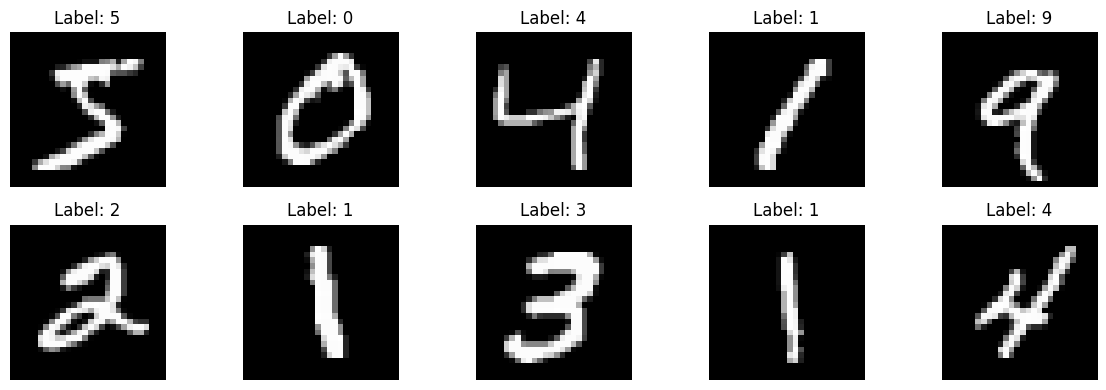

In [8]:
# Display the first 10 handwritten digit images
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 6. Data Preparation

In this step, I will prepare the image data for Machine Learning.

The pixel values in the original images range from 0 to 255. I will divide these values by 255 to convert them into a range between 0 and 1.

This process is called normalization. It helps make the data easier for the model to process.

In [10]:
#Normalize the pixel values
x_train_scaled = X_train.astype('float32') / 255.0
x_test_scaled = X_test.astype('float32') / 255.0

print("Minimum pixel value:", x_train_scaled.min())
print("Maximum pixel value:", x_train_scaled.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 7. Reshaping the Image Data

Each handwritten digit image contains 28 × 28 pixels. Machine Learning algorithms such as Logistic Regression require the image data in a two-dimensional format.

In this step, I will reshape each image into a row containing 784 pixel values. This will prepare the images for model training.

In [12]:
x_train_flat = x_train_scaled.reshape(x_train_scaled.shape[0], 784)
x_test_flat = x_test_scaled.reshape(x_test_scaled.shape[0], 784)

In [14]:
print("Training data shape:", x_train_flat.shape)
print("Testing data shape:", x_test_flat.shape)

Training data shape: (60000, 784)
Testing data shape: (10000, 784)


## 8. Model Training Using Logistic Regression

In this step, I will train a Logistic Regression model using the MNIST dataset.

The model will learn patterns from the pixel values of handwritten digit images and their labels. After training, it will be able to predict digits from 0 to 9.

I will use the training dataset to teach the model how to recognize the digits.

In [15]:
model = LogisticRegression(max_iter=100, solver="lbfgs")

model.fit(x_train_flat, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

## 9. Model Evaluation

In this step, I will evaluate the performance of the trained Logistic Regression model.

I will use the test dataset to check how accurately the model recognizes handwritten digits. I will also use a classification report to understand its performance for different digits.

In [16]:
y_pred = model.predict(x_test_flat)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9256


In [18]:
Cl_Rp = classification_report(y_test, y_pred)
print("Classification Report:\n", Cl_Rp)

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.98      0.96       980
           1       0.96      0.98      0.97      1135
           2       0.93      0.90      0.91      1032
           3       0.90      0.91      0.90      1010
           4       0.94      0.93      0.93       982
           5       0.90      0.87      0.89       892
           6       0.94      0.95      0.94       958
           7       0.94      0.92      0.93      1028
           8       0.88      0.88      0.88       974
           9       0.92      0.92      0.92      1009

    accuracy                           0.93     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.93      0.93      0.93     10000



## 10. Confusion Matrix

A confusion matrix shows how many handwritten digits the model predicted correctly or incorrectly for each digit from 0 to 9.

It helps us understand which digits the model recognizes well and which digits it sometimes confuses with other digits.

In [20]:
CFM = confusion_matrix(y_test, y_pred)
print("Confusion Matrix: \n", CFM)

Confusion Matrix: 
 [[ 959    0    0    3    1    7    5    4    1    0]
 [   0 1112    4    2    0    2    3    2   10    0]
 [   6    9  928   16    8    4   15    7   35    4]
 [   4    1   17  921    0   23    4   11   23    6]
 [   1    1    7    4  914    0   10    4   10   31]
 [  10    2    3   37    8  779   14    5   29    5]
 [   9    3    7    3    8   15  910    2    1    0]
 [   1    9   23    6    7    1    0  950    2   29]
 [   9   10    8   26    8   26   12    7  857   11]
 [   9    8    0   11   23    6    0   19    7  926]]


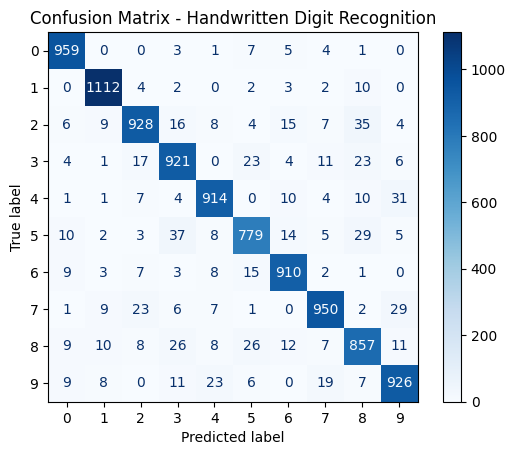

In [21]:
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=CFM,
    display_labels=range(10)
)

display_matrix.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Handwritten Digit Recognition")
plt.show()


## 11. Model Accuracy Visualization

In this step, I will create a bar graph to display the accuracy of my Logistic Regression model.

The graph will help me understand and present the model's performance in a simple visual format.

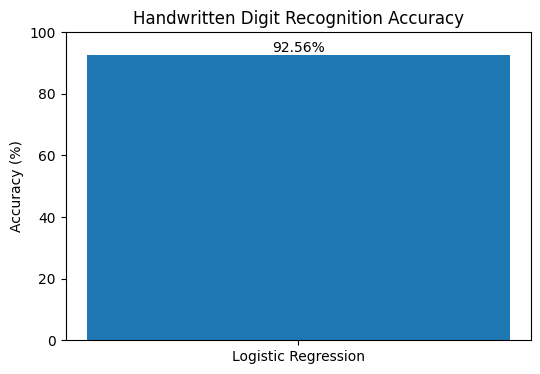

In [22]:

# Visualize model accuracy
accuracy_percentage = accuracy * 100

plt.figure(figsize=(6, 4))
plt.bar(["Logistic Regression"], [accuracy_percentage])

plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Handwritten Digit Recognition Accuracy")

plt.text(
    0,
    accuracy_percentage + 1,
    f"{accuracy_percentage:.2f}%",
    ha="center"
)

plt.show()


## 12. Improving Model Training

The Logistic Regression model displayed a convergence warning during training. In this step, I will increase the maximum number of iterations to give the model more time to find a suitable solution.

I will then evaluate the model again to check whether its accuracy improves.

In [25]:
# Train Logistic Regression with more iterations
improved_model = LogisticRegression(
    max_iter=300,
    solver="lbfgs"
)

improved_model.fit(x_train_flat, y_train)

# Evaluate the improved model
improved_pred = improved_model.predict(x_test_flat)
improved_accuracy = accuracy_score(y_test, improved_pred)

print("Previous Accuracy:", round(accuracy * 100, 2), "%")
print("New Accuracy:", round(improved_accuracy * 100, 2), "%")

Previous Accuracy: 92.56 %
New Accuracy: 92.64 %


## 14. Final Model Results

In this project, I developed a Handwritten Digit Recognition model using Python and Machine Learning.

The MNIST dataset was used to train and test the model. Each image was normalized and converted into numerical features for Logistic Regression.

The initial model achieved 92.56% accuracy. After increasing the maximum number of training iterations, the accuracy improved to 92.64%.

The model was also tested using sample handwritten digit images to compare actual and predicted labels.

This project helped me understand image classification, data preparation, model training, and performance evaluation.